# 05 — Qini, Decile Lift, and Top-k Policy Value

**Question.** Given a fitted uplift model, how much campaign value can we expect at each budget level, and where is the cut-off between a useful and a wasteful contact?

This notebook is the bridge from *scores* to *decisions*. It produces three views of the same ranking:

1. The Qini curve — global ranking quality.
2. Decile lift — local sanity check that the top of the ranking really has positive observed uplift.
3. Top-k policy value — what a campaign of size $k$ buys, given the actual treated/control behaviour inside the selected segment.


In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


In [2]:
from sklearn.model_selection import train_test_split

from uplift_marketing.features import infer_feature_spec, split_features_treatment_outcome
from uplift_marketing.models import TLearner
from uplift_marketing.uplift import attach_uplift_scores, make_uplift_deciles, uplift_by_group
from uplift_marketing.evaluation import qini_curve, area_under_qini, policy_value_at_fraction
from uplift_marketing.policy import assign_campaign_segments, campaign_action_table

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)
x, treatment, y = split_features_treatment_outcome(data, spec)

x_tr, x_te, t_tr, t_te, y_tr, y_te, raw_tr, raw_te = train_test_split(
    x, treatment, y, data,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=treatment.astype(str) + "_" + y.astype(str),
)
model = TLearner(spec=spec, random_state=RANDOM_STATE).fit(x_tr, t_tr, y_tr)
p_control, p_treated = model.predict_potential_outcomes(x_te)
scored = attach_uplift_scores(raw_te.reset_index(drop=True), p_control=p_control, p_treated=p_treated)
scored["uplift_decile"] = make_uplift_deciles(scored)
scored[["p_control", "p_treated", "uplift_score", "uplift_decile"]].describe().T

,count,mean,std,min,25%,50%,75%,max
p_control,19200.0,0.432669,0.180961,0.083889,0.292036,0.420638,0.570882,0.905380
p_treated,19200.0,0.472819,0.111450,0.231015,0.392279,0.460669,0.542240,0.862708
uplift_score,19200.0,0.040150,0.116069,-0.246534,-0.049599,0.049942,0.129425,0.407506
uplift_decile,19200.0,5.500000,2.872356,1.000000,3.000000,5.500000,8.000000,10.000000


## 1. Qini curve and area

Compared to a random ranking, the model's lift over the diagonal is the incremental value of *using the model* — not of running the campaign at all.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
curve_model = qini_curve(
    outcome=scored["conversion"].to_numpy(),
    treatment=scored["treatment"].to_numpy(),
    uplift_score=scored["uplift_score"].to_numpy(),
)
curve_random = qini_curve(
    outcome=scored["conversion"].to_numpy(),
    treatment=scored["treatment"].to_numpy(),
    uplift_score=rng.uniform(size=len(scored)),
)
auq_model = area_under_qini(curve_model)
auq_random = area_under_qini(curve_random)
print(f"AUQ T-learner: {auq_model:.4f}")
print(f"AUQ random:    {auq_random:.4f}")
print(f"AUQ lift over random: {auq_model - auq_random:+.4f}")

AUQ T-learner: 34.8166
AUQ random:    36.4493
AUQ lift over random: -1.6327


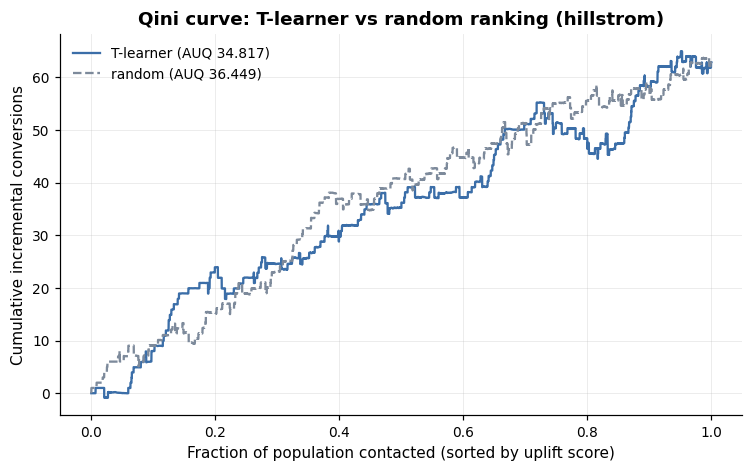

In [4]:
fig, ax = plt.subplots()
ax.plot(curve_model["population_fraction"], curve_model["incremental_gain"],
        label=f"T-learner (AUQ {auq_model:.3f})", color="#3b6ea8")
ax.plot(curve_random["population_fraction"], curve_random["incremental_gain"],
        label=f"random (AUQ {auq_random:.3f})", color="#7d8a9b", linestyle="--")
ax.set_xlabel("Fraction of population contacted (sorted by uplift score)")
ax.set_ylabel("Cumulative incremental conversions")
ax.set_title(f"Qini curve: T-learner vs random ranking ({dataset.source})")
ax.legend()
save_figure(fig, "05_qini_curve")
plt.show()

## 2. Decile lift

The Qini curve is monotone by construction; the decile view exposes whether the highest-scoring deciles really do convert at a higher rate under treatment than under control.

In [5]:
decile = uplift_by_group(scored, group_col="uplift_decile")
decile

,uplift_decile,n,treated_n,control_n,treated_rate,control_rate,observed_uplift
0,1,1920,1281,639,0.009368,0.003130,0.006238
1,2,1920,1289,631,0.013964,0.001585,0.012380
2,3,1920,1304,616,0.008436,0.008117,0.000319
3,4,1920,1260,660,0.010317,0.006061,0.004257
4,5,1920,1249,671,0.007206,0.002981,0.004225
5,6,1920,1280,640,0.006250,0.004687,0.001563
6,7,1920,1289,631,0.012413,0.001585,0.010828
7,8,1920,1260,660,0.008730,0.012121,-0.003391
8,9,1920,1294,626,0.017002,0.007987,0.009014
9,10,1920,1302,618,0.013057,0.009709,0.003348


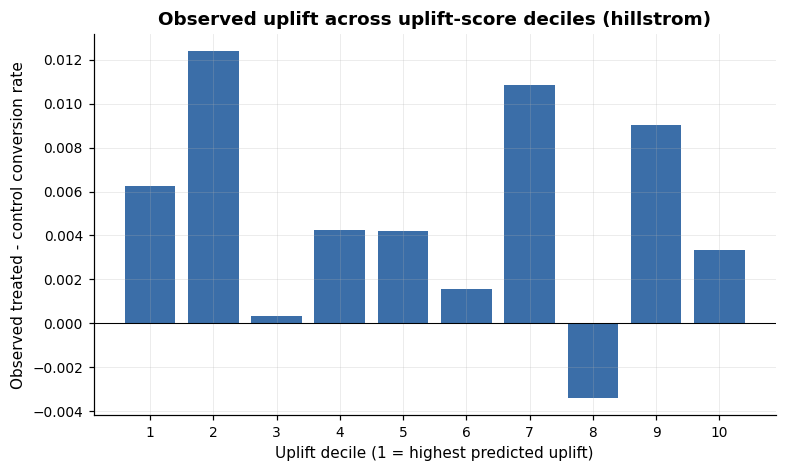

In [6]:
fig, ax = plt.subplots()
ax.bar(decile["uplift_decile"], decile["observed_uplift"], color="#3b6ea8")
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xticks(decile["uplift_decile"])
ax.set_xlabel("Uplift decile (1 = highest predicted uplift)")
ax.set_ylabel("Observed treated - control conversion rate")
ax.set_title(f"Observed uplift across uplift-score deciles ({dataset.source})")
save_figure(fig, "05_decile_lift")
plt.show()

## 3. Top-k policy value

For each candidate budget fraction, contact the top-$k$ customers and observe the treated-control gap *inside that segment*. Because the data is randomized, the within-segment gap is an honest estimate of the campaign's incremental effect on those customers.

In [7]:
fractions = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.75, 1.00]
policy = pd.DataFrame(
    [policy_value_at_fraction(scored, fraction=f) for f in fractions]
)
policy

,fraction,selected_n,treated_rate,control_rate,observed_uplift
0,0.05,960.0,0.003140,0.003096,0.000044
1,0.10,1920.0,0.009368,0.003130,0.006238
2,0.15,2880.0,0.011936,0.002099,0.009837
3,0.20,3840.0,0.011673,0.002362,0.009311
4,0.25,4800.0,0.010615,0.003757,0.006858
5,0.30,5760.0,0.010583,0.004242,0.006342
6,0.40,7680.0,0.010518,0.004713,0.005805
7,0.50,9600.0,0.009870,0.004352,0.005518
8,0.75,14400.0,0.009922,0.004560,0.005362
9,1.00,19200.0,0.010696,0.005788,0.004908


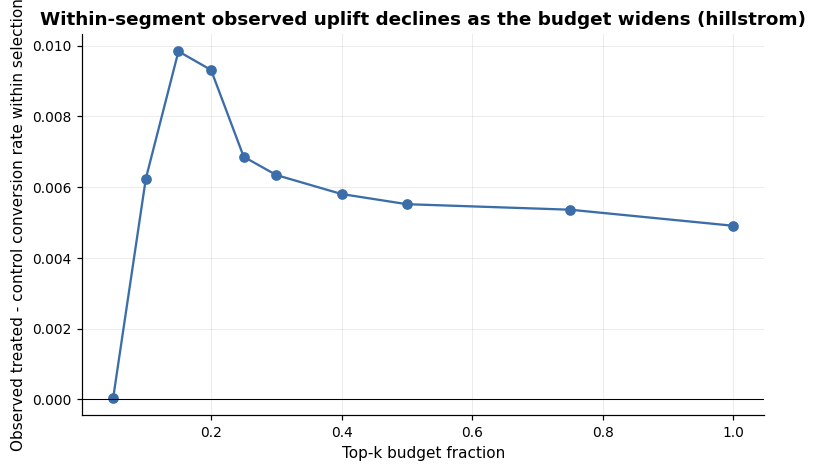

In [8]:
fig, ax = plt.subplots()
ax.plot(policy["fraction"], policy["observed_uplift"], marker="o", color="#3b6ea8")
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xlabel("Top-k budget fraction")
ax.set_ylabel("Observed treated - control conversion rate within selection")
ax.set_title(
    f"Within-segment observed uplift declines as the budget widens "
    f"({dataset.source})"
)
save_figure(fig, "05_top_k_policy_value")
plt.show()

## 4. From scores to segments

The action table summarises the model's recommendation in business language: persuadable / sure-thing / lost-cause / do-not-disturb / review. Segment cuts are configurable in [`policy.assign_campaign_segments`](../src/uplift_marketing/policy.py).

In [9]:
scored["campaign_segment"] = assign_campaign_segments(scored)
actions = campaign_action_table(scored)
actions

,campaign_segment,n,share,mean_uplift,median_uplift,mean_p_control,mean_p_treated,recommended_action,caution
1,persuadable,3087,0.160781,0.203086,0.193548,0.257078,0.460165,Target with campaign. These customers appear r...,Validate incrementality in holdout tests befor...
2,review,8626,0.449271,0.087260,0.087951,0.354733,0.441993,Keep under review. The estimated effect is unc...,Use business context and experimentation befor...
0,do_not_disturb,222,0.011562,-0.011661,-0.008614,0.372450,0.360789,Avoid treatment. The estimated effect is negat...,Investigate whether treatment fatigue or poor ...
3,sure_thing,7265,0.378385,-0.083437,-0.081274,0.601658,0.518221,Avoid aggressive targeting. They may convert w...,Do not confuse high conversion probability wit...


## 5. Takeaway

- AUQ over a single test split is noisy on rare-event data — small differences between the model curve and the random baseline reflect sample noise as much as model quality. The decile and top-k views below are more direct.
- The decile bar chart can be jagged when conversions are rare, but the top-$k$ policy table is cleaner: within-segment observed uplift in the top fractions is materially higher than the population ATE, falling toward the population mean as the budget widens.
- The right budget is where the marginal contact's uplift just covers its cost. Notebook 06 makes that condition explicit and shows it produces a clean interior optimum.
